# 🏥 Medical Insurance Cost Prediction
## End-to-End Data Science Project
**Features:** age, sex, bmi, children, smoker, region → **Target:** charges


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error

plt.style.use('dark_background')
print('✅ Libraries loaded')

✅ Libraries loaded


## 1. Load & Explore Data

In [4]:
df = pd.read_csv('../data/insurance.csv')
print(f'Shape: {df.shape}')
df.head()

Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,56,male,27.12,2,no,northwest,15728.17
1,46,female,29.50,1,no,southwest,10381.77
2,32,male,26.07,5,no,northwest,14831.01
3,60,male,30.90,1,no,northwest,19292.34
4,25,male,26.91,0,no,southwest,8175.15


In [5]:
print('=== Data Types ===')
print(df.dtypes)
print('\n=== Missing Values ===')
print(df.isnull().sum())
print('\n=== Descriptive Statistics ===')
df.describe()

=== Data Types ===
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

=== Missing Values ===
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

=== Descriptive Statistics ===


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,41.036622,30.547668,1.067265,19997.959522
std,13.528861,5.968852,1.232187,15101.224822
min,18.000000,15.960000,0.000000,5381.700000
25%,29.000000,26.432500,0.000000,10998.962500
50%,42.000000,30.720000,1.000000,14200.135000
75%,52.000000,34.610000,2.000000,19063.347500
max,64.000000,47.360000,5.000000,79636.390000


## 2. EDA — Exploratory Data Analysis

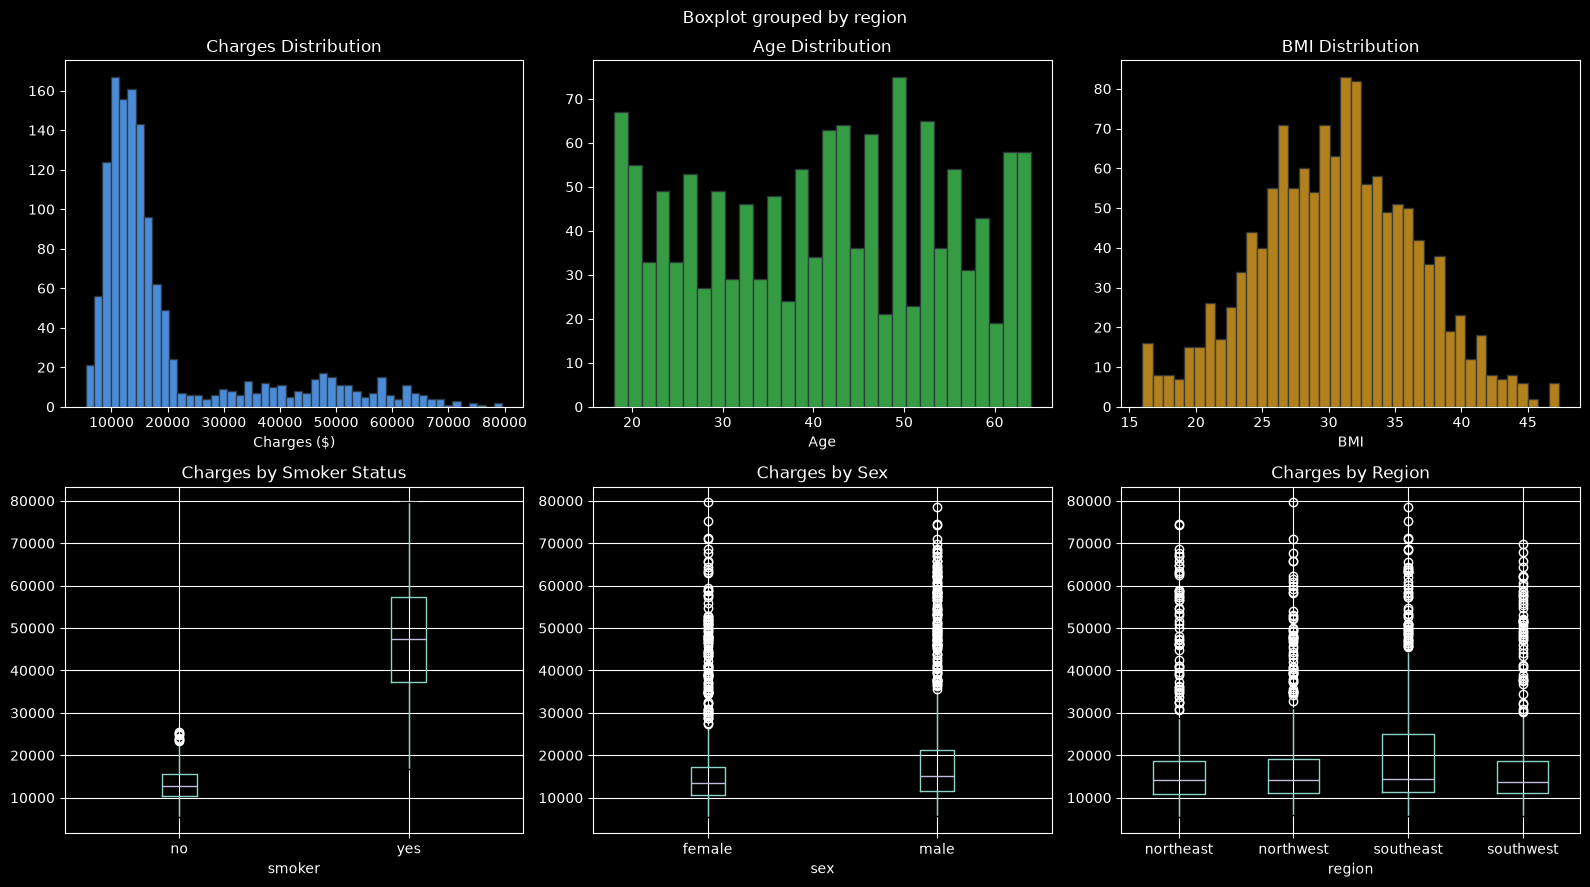

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Insurance Dataset — EDA Overview', fontsize=16, y=1.02)

# Charges distribution
axes[0,0].hist(df['charges'], bins=50, color='#58a6ff', edgecolor='#30363d', alpha=0.85)
axes[0,0].set_title('Charges Distribution'); axes[0,0].set_xlabel('Charges ($)')

# Age distribution
axes[0,1].hist(df['age'], bins=30, color='#3fb950', edgecolor='#30363d', alpha=0.85)
axes[0,1].set_title('Age Distribution'); axes[0,1].set_xlabel('Age')

# BMI distribution
axes[0,2].hist(df['bmi'], bins=40, color='#d29922', edgecolor='#30363d', alpha=0.85)
axes[0,2].set_title('BMI Distribution'); axes[0,2].set_xlabel('BMI')

# Smoker vs charges
df.boxplot(column='charges', by='smoker', ax=axes[1,0])
axes[1,0].set_title('Charges by Smoker Status')

# Sex vs charges
df.boxplot(column='charges', by='sex', ax=axes[1,1])
axes[1,1].set_title('Charges by Sex')

# Region vs charges
df.boxplot(column='charges', by='region', ax=axes[1,2])
axes[1,2].set_title('Charges by Region')

plt.tight_layout()
plt.show()

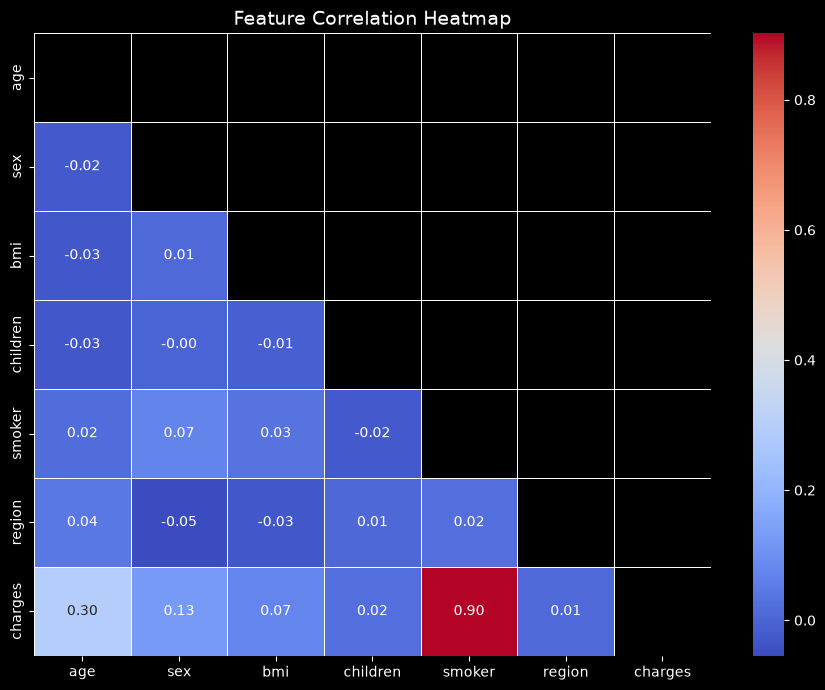

In [7]:
# Correlation heatmap after encoding
df_enc = df.copy()
for col in ['sex','smoker','region']:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col])

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones(df_enc.corr().shape, dtype=bool))
sns.heatmap(df_enc.corr(), annot=True, fmt='.2f', cmap='coolwarm', mask=mask,
            linewidths=0.5, annot_kws={'size':10})
plt.title('Feature Correlation Heatmap', fontsize=14)
plt.tight_layout()
plt.show()

## 3. Feature Engineering & Preprocessing

In [8]:
df_ml = df.copy()
le_sex    = LabelEncoder(); df_ml['sex']    = le_sex.fit_transform(df_ml['sex'])
le_smoker = LabelEncoder(); df_ml['smoker'] = le_smoker.fit_transform(df_ml['smoker'])
le_region = LabelEncoder(); df_ml['region'] = le_region.fit_transform(df_ml['region'])

X = df_ml.drop('charges', axis=1)
y = df_ml['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
print('✅ Preprocessing complete')

Train: (1070, 6), Test: (268, 6)
✅ Preprocessing complete


## 4. Train & Evaluate Models

In [9]:
results = {}

# Linear Regression (scaled)
lr = LinearRegression()
lr.fit(X_train_s, y_train)
lr_preds = lr.predict(X_test_s)
results['Linear Regression'] = {
    'r2':   round(r2_score(y_test, lr_preds), 4),
    'rmse': round(np.sqrt(mean_squared_error(y_test, lr_preds)), 2)
}

# Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)
results['Random Forest'] = {
    'r2':   round(r2_score(y_test, rf_preds), 4),
    'rmse': round(np.sqrt(mean_squared_error(y_test, rf_preds)), 2)
}

# Gradient Boosting
gb = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)
gb_preds = gb.predict(X_test)
results['Gradient Boosting'] = {
    'r2':   round(r2_score(y_test, gb_preds), 4),
    'rmse': round(np.sqrt(mean_squared_error(y_test, gb_preds)), 2)
}

results_df = pd.DataFrame(results).T
print('=== Model Comparison ===')
print(results_df.sort_values('r2', ascending=False))

=== Model Comparison ===
                       r2     rmse
Random Forest      0.9402  3752.32
Gradient Boosting  0.9386  3802.15
Linear Regression  0.9008  4833.54


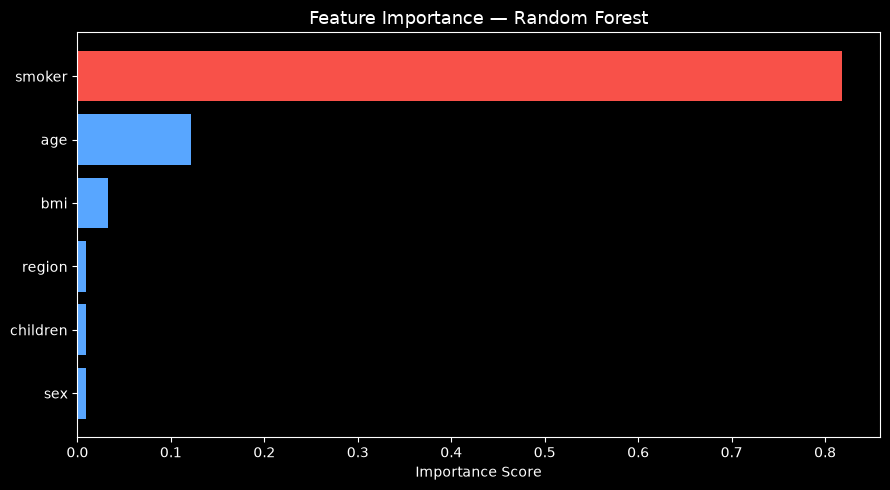

In [10]:
# Feature Importance
feat_names = list(X.columns)
importances = rf.feature_importances_
sorted_idx  = np.argsort(importances)

plt.figure(figsize=(9, 5))
colors = ['#f85149' if importances[i]==max(importances) else '#58a6ff' for i in sorted_idx]
plt.barh([feat_names[i] for i in sorted_idx], [importances[i] for i in sorted_idx], color=colors)
plt.title('Feature Importance — Random Forest', fontsize=13)
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

## 5. Save Best Model

In [13]:
best_model_name = max(results, key=lambda x: results[x]['r2'])
best_model = {'Linear Regression': lr, 'Random Forest': rf, 'Gradient Boosting': gb}[best_model_name]
print(f'Best model: {best_model_name} — R²={results[best_model_name]["r2"]}')

bundle = {
    'model': best_model, 'scaler': scaler,
    'le_sex': le_sex, 'le_smoker': le_smoker, 'le_region': le_region,
    'best_model_name': best_model_name,
    'features': feat_names,
    'use_scaler': best_model_name == 'Linear Regression'
}
with open('../model/model_bundle1.pkl', 'wb') as f:
    pickle.dump(bundle, f)
print('✅ Model bundle saved!')

Best model: Random Forest — R²=0.9402
✅ Model bundle saved!
